[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zjelveh/zjelveh.github.io/blob/master/files/ccjs418e_fall2026/8_visualization.ipynb)

**Save your own copy.**
1. Click File > Save a copy in Drive.
2. Rename it.
3. Work in your copy.

---

# 8. Data Visualization: Seeing Comparisons
## CCJS 418E: Coding for Criminology — Fall 2026

We have used filtering, groupby, and calculations to answer questions with arrest records. Today we will turn summary tables into charts.

Our questions are:

- Which boroughs recorded more arrests, and how did the counts change across years?
- How did average arrests per day change over time?
- On days with more felony arrests, were there also more misdemeanor arrests?

We will use **bar charts**, **line charts**, and **scatterplots**. The same small set of arguments—`data=`, `x=`, `y=`, and `hue=`—will appear throughout.

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

np.set_printoptions(legacy="1.25")
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 4)

## Setup: Daily Arrest Counts

We will use a prepared summary of the same New York City arrest extract as the datetime notebook. The file covers 2013–2015.

**One row represents one date in one borough.** The file includes every date-borough combination, including counts of zero.

| Column | Meaning |
|---|---|
| `date` | Calendar date |
| `year`, `month` | Year and month number |
| `month_start` | First date of that calendar month |
| `borough` | Borough name |
| `arrests` | Total recorded felony and misdemeanor arrests |
| `felony_arrests` | Recorded felony arrests |
| `misdemeanor_arrests` | Recorded misdemeanor arrests |

Load the prepared CSV, convert its two date columns, and inspect the rows. We will build each chart's table with short groupby steps beside the example.

In [2]:
data_url = 'https://raw.githubusercontent.com/zjelveh/zjelveh.github.io/refs/heads/master/files/ccjs418e_fall2026/nypd_arrests_daily_borough.csv'
df = pd.read_csv(filepath_or_buffer=data_url)
df['date'] = pd.to_datetime(arg=df['date'])
df['month_start'] = pd.to_datetime(arg=df['month_start'])

df.head(n=5)
df.shape

,date,year,month,month_start,borough,arrests,felony_arrests,misdemeanor_arrests
0,2013-01-01,2013,1,2013-01-01,Bronx,143,33,110
1,2013-01-01,2013,1,2013-01-01,Brooklyn,262,87,175
2,2013-01-01,2013,1,2013-01-01,Manhattan,192,44,148
3,2013-01-01,2013,1,2013-01-01,Queens,184,48,136
4,2013-01-01,2013,1,2013-01-01,Staten Island,23,8,15


(5475, 8)

## Part 1: Bar Charts Compare Categories

**Question:** Which borough recorded the most arrests in 2014?

First select 2014. Then add the daily counts within each borough using `.groupby()` and `.sum()`. The resulting table has one row per borough.

In [3]:
arrests_2014 = df[df['year'] == 2014]
boroughs_2014 = arrests_2014.groupby(by=['borough'])['arrests'].sum().reset_index()
boroughs_2014

,borough,arrests
0,Bronx,82690
1,Brooklyn,95174
2,Manhattan,93787
3,Queens,69454
4,Staten Island,13221


<Axes: xlabel='borough', ylabel='arrests'>

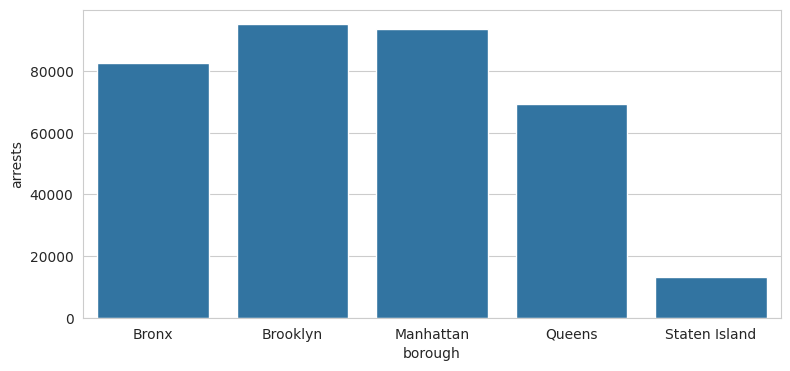

In [4]:
sns.barplot(
    data=boroughs_2014,
    x='borough',
    y='arrests'
)

### Read the Function Call

| Argument | What it selects |
|---|---|
| `data=boroughs_2014` | The table containing the plotted values |
| `x='borough'` | The categories on the horizontal axis |
| `y='arrests'` | The column supplying bar heights |

Each bar shows a borough's recorded arrest count for 2014. A taller bar means more recorded arrests in this file.

Look back at the table: which row supplies the tallest bar?

### Add a Second Comparison with `hue`

**Question:** How did recorded arrest counts differ between 2014 and 2015 in each borough?

Select those two years and group by both borough and year. Each borough now has two rows: one per year.

Adding `hue='year'` gives the two years different colors.

In [5]:
comparison_years = df[df['year'].isin(values=[2014, 2015])]
borough_years = comparison_years.groupby(by=['borough', 'year'])['arrests'].sum().reset_index()
borough_years.head(n=6)

,borough,year,arrests
0,Bronx,2014,82690
1,Bronx,2015,72406
2,Brooklyn,2014,95174
3,Brooklyn,2015,83892
4,Manhattan,2014,93787
5,Manhattan,2015,83602


<Axes: xlabel='borough', ylabel='arrests'>

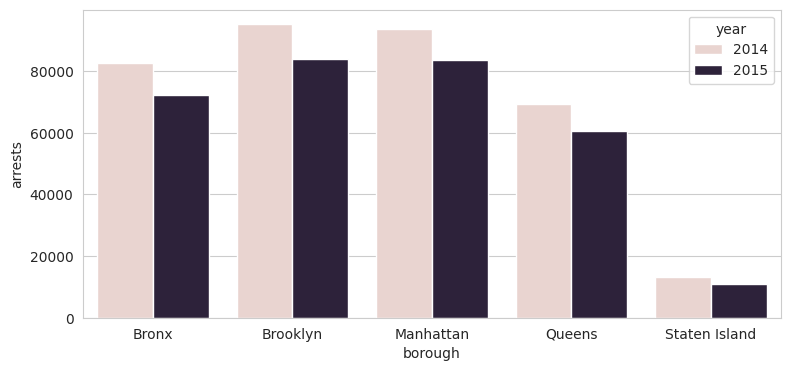

In [6]:
sns.barplot(
    data=borough_years,
    x='borough',
    y='arrests',
    hue='year'
)

### Read the Comparison

Compare the two bars within each borough, then compare the same color across boroughs.

- Which borough recorded the most arrests in each year?
- Where is the gap between the years largest?

Both charts display counts. A comparison of arrest rates per resident would also require population information.

## Part 2: Line Charts Show Change Over Time

**Question:** How did average arrests per day change from 2013 through 2015?

Start by adding the five boroughs' counts for each date. Keep `month_start` alongside the date so we can group the daily totals into months next.

The `daily_arrests` table has one row per date for the whole city.

In [7]:
daily_arrests = df.groupby(by=['date', 'month_start'])[
    ['arrests', 'felony_arrests', 'misdemeanor_arrests']
].sum().reset_index()
daily_arrests['year'] = daily_arrests['date'].dt.year

daily_arrests.head(n=5)

,date,month_start,arrests,felony_arrests,misdemeanor_arrests,year
0,2013-01-01,2013-01-01,804,220,584,2013
1,2013-01-02,2013-01-01,1084,296,788,2013
2,2013-01-03,2013-01-01,1230,341,889,2013
3,2013-01-04,2013-01-01,1165,334,831,2013
4,2013-01-05,2013-01-01,978,253,725,2013


### Average the Daily Counts Within Each Month

Group the citywide daily totals by `month_start` and calculate their mean. The resulting `arrests_per_day` column is the month's average daily count. Each row of `monthly_arrests` represents one calendar month.

The same `.dt.year` and `.dt.month` operations from the datetime lesson give us columns for comparing years.

In [8]:
monthly_arrests = daily_arrests.groupby(by=['month_start'])['arrests'].mean().reset_index(name='arrests_per_day')
monthly_arrests['year'] = monthly_arrests['month_start'].dt.year
monthly_arrests['month'] = monthly_arrests['month_start'].dt.month

monthly_arrests.head(n=5)

,month_start,arrests_per_day,year,month
0,2013-01-01,1000.580645,2013,1
1,2013-02-01,1037.107143,2013,2
2,2013-03-01,1003.967742,2013,3
3,2013-04-01,1057.233333,2013,4
4,2013-05-01,1058.354839,2013,5


<Axes: xlabel='month_start', ylabel='arrests_per_day'>

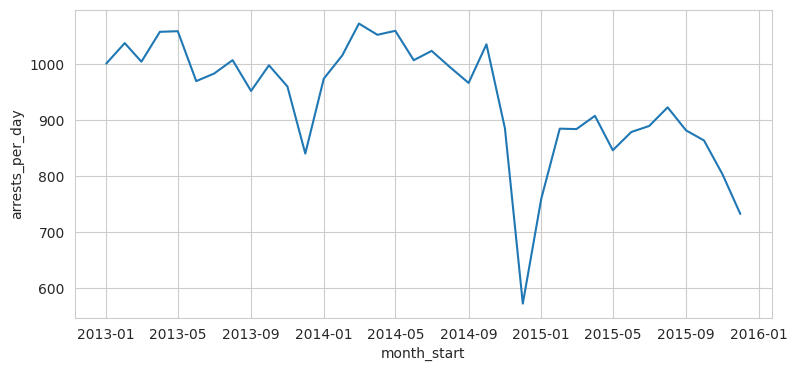

In [9]:
sns.lineplot(
    data=monthly_arrests,
    x='month_start',
    y='arrests_per_day'
)

### Read the Time Axis and Units

A point near 900 means an average of about 900 recorded arrests per day during that month. The line connects the monthly averages in date order.

Follow the line across the end of 2014 and into 2015. Describe the size and timing of the change you see.

Starting with one count per date lets `.mean()` account for the different numbers of days in calendar months.

### Compare the Same Months Across Years

**Question:** Did the end-of-year pattern look similar in each year?

Use `month` on the horizontal axis and `hue='year'` to draw a separate line for each year. January is 1 and December is 12.

There is one value for each month-year combination in this table.

<Axes: xlabel='month', ylabel='arrests_per_day'>

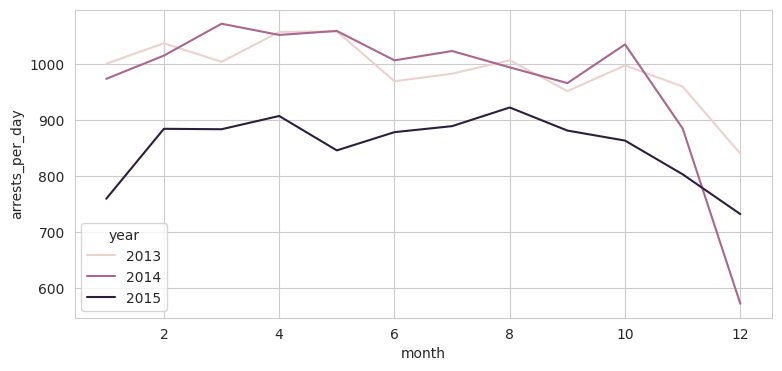

In [10]:
sns.lineplot(
    data=monthly_arrests,
    x='month',
    y='arrests_per_day',
    hue='year'
)

## Part 3: Scatterplots Compare Two Numerical Measures

**Question:** On days with more felony arrests, were there also more misdemeanor arrests?

Use `daily_arrests`. One row represents one date and contains both counts for that same date.

Start with the dates in 2014.

In [11]:
daily_2014 = daily_arrests[daily_arrests['year'] == 2014]
daily_2014.head(n=5)

,date,month_start,arrests,felony_arrests,misdemeanor_arrests,year
365,2014-01-01,2014-01-01,948,245,703,2014
366,2014-01-02,2014-01-01,971,256,715,2014
367,2014-01-03,2014-01-01,565,134,431,2014
368,2014-01-04,2014-01-01,837,237,600,2014
369,2014-01-05,2014-01-01,568,107,461,2014


<Axes: xlabel='felony_arrests', ylabel='misdemeanor_arrests'>

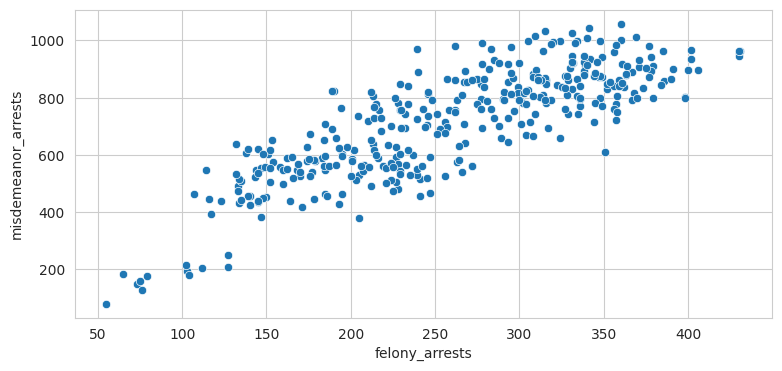

In [12]:
sns.scatterplot(
    data=daily_2014,
    x='felony_arrests',
    y='misdemeanor_arrests'
)

### What Does One Dot Represent?

Each dot represents **one date in 2014**.

- Its horizontal position shows that day's felony arrest count.
- Its vertical position shows that day's misdemeanor arrest count.
- A dot farther right and higher up represents a date with larger counts of both categories.

Look for the overall direction, how tightly the dots cluster, and any dates that stand apart. Do higher felony counts generally accompany higher misdemeanor counts?

Each dot puts two counts side by side for the same date. Describe their relationship across dates.

### Make Overlapping Dots Easier to See

`alpha` controls transparency. A value of 1 is fully opaque; a smaller value lets overlapping dots show through.

Run the same scatterplot with `alpha=0.4`. What becomes easier to see?

<Axes: xlabel='felony_arrests', ylabel='misdemeanor_arrests'>

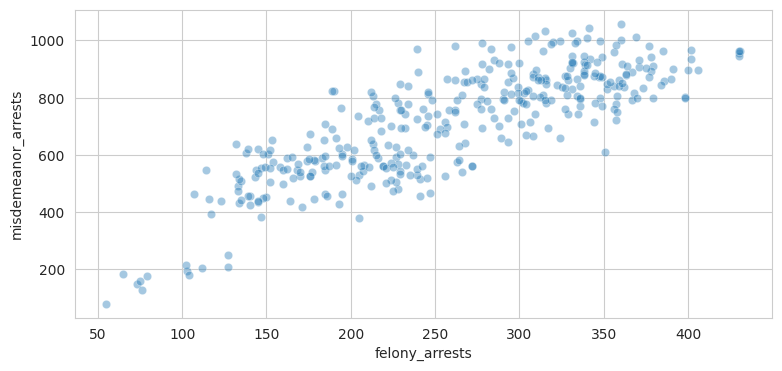

In [13]:
sns.scatterplot(
    data=daily_2014,
    x='felony_arrests',
    y='misdemeanor_arrests',
    alpha=0.4
)

## Finishing a Chart: Titles and Axis Labels

Once the chart answers the question, add a title and units so another reader can understand it.

Seaborn creates the chart. The three `plt` calls below add its title and axis labels. Here is the earlier bar chart with those additions.

<Axes: xlabel='borough', ylabel='arrests'>

Text(0.5, 1.0, 'Recorded Arrests by Borough, 2014')

Text(0.5, 0, 'Borough')

Text(0, 0.5, 'Recorded arrests')

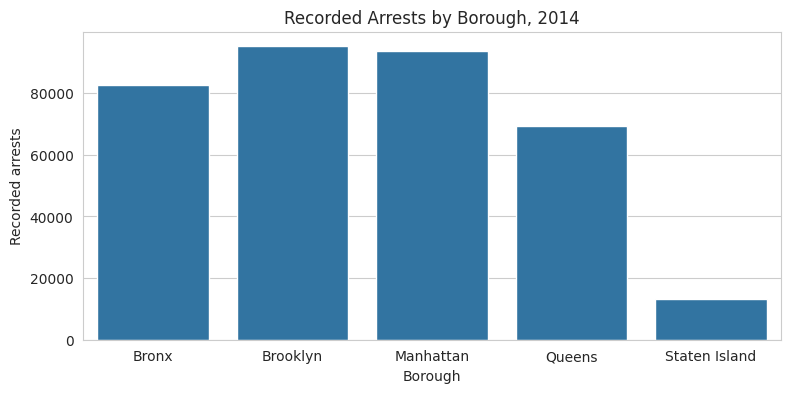

In [14]:
sns.barplot(data=boroughs_2014, x='borough', y='arrests')
plt.title(label='Recorded Arrests by Borough, 2014')
plt.xlabel(xlabel='Borough')
plt.ylabel(ylabel='Recorded arrests')

## Hands-On Exercises

Each exercise has two parts. Part A repeats an example with a different selection. Part B changes the comparison.

Use the summary tables we created, show your plots, and discuss the questions below. Add titles and units when you are ready to present a chart.

### Exercise 1: Borough Comparisons

**Part A:** Filter `df` to 2015. Group by borough and sum `arrests`, then create a bar chart.

**Part B:** Use `.isin()` to select 2013 and 2015. Group by borough and year, sum `arrests`, and create a grouped bar chart with `hue='year'`.

**Question:** Did the borough with the most arrests stay the same across those two years? Where is the change largest? Use your charts to explain.

In [ ]:
# Part A: Select 2015, sum arrests by borough, and create a bar chart.

In [ ]:
# Part B: Select 2013 and 2015, sum by borough and year, and add hue='year'.

### Exercise 2: One Year's Trend and a Comparison

**Part A:** Filter `monthly_arrests` to 2015. Plot average arrests per day against `month_start`.

**Part B:** Use `.isin()` to select 2014 and 2015. Put `month` on the horizontal axis and use `hue='year'` to compare the two years on the same chart.

**Question:** What does the second chart help you notice about 2015 that is harder to see in the first chart?

In [ ]:
# Part A: Select 2015 and plot arrests_per_day against month_start.

In [ ]:
# Part B: Select 2014 and 2015, then compare calendar months with hue='year'.

### Exercise 3: Compare the Relationship Across Years

**Part A:** Filter `daily_arrests` to 2013. Create a scatterplot with felony arrests on the horizontal axis and misdemeanor arrests on the vertical axis.

**Part B:** Use `.isin()` to select 2013 and 2015. Plot both years together with `hue='year'` and `alpha=0.4`.

**Question:** How much do the two years' dots overlap? Can dates in the two years have similar felony counts but different misdemeanor counts? Explain with reference to the plot.

In [ ]:
# Part A: Select 2013 and plot felony_arrests against misdemeanor_arrests.

In [ ]:
# Part B: Select 2013 and 2015, then add hue='year' and alpha=0.4.

## Reference: Choose a Chart for the Question

| Question | Chart | What one mark represents in our examples |
|---|---|---|
| How do boroughs compare across years? | Bar chart | One borough's arrest count for a selected year |
| How does arrest activity change over time? | Line chart | One month's average arrests per day |
| How do two daily counts vary together? | Scatterplot | One date, positioned using its felony and misdemeanor counts |

```python
sns.barplot(data=table, x='category_column', y='value_column')
sns.lineplot(data=table, x='date_column', y='value_column')
sns.scatterplot(data=table, x='first_measure', y='second_measure')

# Compare groups with color
sns.lineplot(data=table, x='time_column', y='value_column', hue='group_column')

# Add transparency to a scatterplot
sns.scatterplot(data=table, x='first_measure', y='second_measure', alpha=0.4)
```

## From a Table to an Answer

For each chart:

1. State the question and the comparison.
2. Check what one row of the plotted table represents.
3. Select the table and columns with `data`, `x`, and `y`.
4. Use `hue` when comparing groups.
5. Describe the pattern using the chart's dates, categories, and units.

The PPI reading makes a related choice visible: counting jail admissions across a year and counting people held on one day produce different comparisons. Start by identifying what the records and plotted values represent.